<a href="https://colab.research.google.com/github/ninkkka/data_analysis_labs/blob/main/lab1/lab1_hierarchical_clustering.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

# **Лабораторная работа №1**

## **Иерархический кластерный анализ**

**Тема**: Сегментация потребителей леденцов по мотивам потребления

**Цель**: Выделить группы потребителей со схожими потребностями с помощью иерархической кластеризации

In [1]:
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns
from scipy.cluster.hierarchy import linkage, dendrogram, fcluster
from sklearn.metrics import silhouette_score, adjusted_rand_score

# **1. Загрузка данных и первичный анализ**
Для начала загрузим данные и посмотрим, как они устроены. Проверим количество наблюдений и признаков, наличие пропусков и повторяющихся строк. Также рассчитаем основные статистические показатели, чтобы получить общее представление о данных

Каждая строчка таблицы соответствует одному участнику опрса, а столбцы V1-V2 содержат оценки различных мотивов употребления леденцов

In [2]:
df = pd.read_csv('Леденцы.dat', sep=';')
df.head()

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
0,4,5,5,5,3,3,3,3,3,3,3
1,5,4,5,5,3,3,3,3,3,3,3
2,5,5,4,5,3,3,3,3,3,3,3
3,5,4,5,5,3,3,3,3,3,3,3
4,4,5,5,5,3,3,3,3,3,3,3


In [3]:
print(f'Размер таблицы: {df.shape}')
print(f'\nИнформация о данных:')
df.info()

Размер таблицы: (338, 11)

Информация о данных:
<class 'pandas.core.frame.DataFrame'>
RangeIndex: 338 entries, 0 to 337
Data columns (total 11 columns):
 #   Column  Non-Null Count  Dtype
---  ------  --------------  -----
 0   V1      338 non-null    int64
 1   V2      338 non-null    int64
 2   V3      338 non-null    int64
 3   V4      338 non-null    int64
 4   V5      338 non-null    int64
 5   V6      338 non-null    int64
 6   V7      338 non-null    int64
 7   V8      338 non-null    int64
 8   V9      338 non-null    int64
 9   V10     338 non-null    int64
 10  V11     338 non-null    int64
dtypes: int64(11)
memory usage: 29.2 KB


В таблице 338 строк и 11 столбцов, то бишь 338 наблюдений и 11 признаков

In [4]:
print('Проспуски по столбцам:')
print(df.isnull().sum())
print(f'\nКоличество дубликотов: {df.duplicated().sum()}')

Проспуски по столбцам:
V1     0
V2     0
V3     0
V4     0
V5     0
V6     0
V7     0
V8     0
V9     0
V10    0
V11    0
dtype: int64

Количество дубликотов: 293


Из 338 респондентов 293 полностью совпадающих комбинаций ответов. В реалиях текущих данных это не выглядит как ошибка, вполне может быть такое, что у такого количество опрашиваемых полностью совпали утверждения

Поэтому дубликаты не удаляем

In [5]:
df.describe().round(2)

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
count,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00,338.00
mean,3.54,3.53,3.52,3.41,3.21,3.20,3.25,3.29,3.60,3.55,3.57
std,0.96,0.96,0.99,0.99,0.87,0.87,0.84,0.82,0.97,0.93,0.94
min,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00,2.00
25%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
50%,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00,3.00
75%,5.00,5.00,5.00,4.00,3.00,3.00,3.00,3.00,5.00,5.00,5.00
max,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00,5.00


- Средние значения признаков находятся в диапазоне от 3,2 до 3,6. Наибольшая средняя оценка соответствует утверждению V9 (облегчение боли в горле), наименьшая - V6 (желание съесть что-нибудь сладкое)
- Стандартное отклонение находится в диапазоне от 0,82 до 0,99, что свидетельствует о различиях в ответах респондентов


# **2. Распределение признаков**
Далее построим столбчатые диаграммы для всех 11 признаков для демонстрации того, сколько респондентов выбрали каждую оценку

Это поможет понять, насколько разнообразы ответы и какие мотивы чаще получают высокие оценки

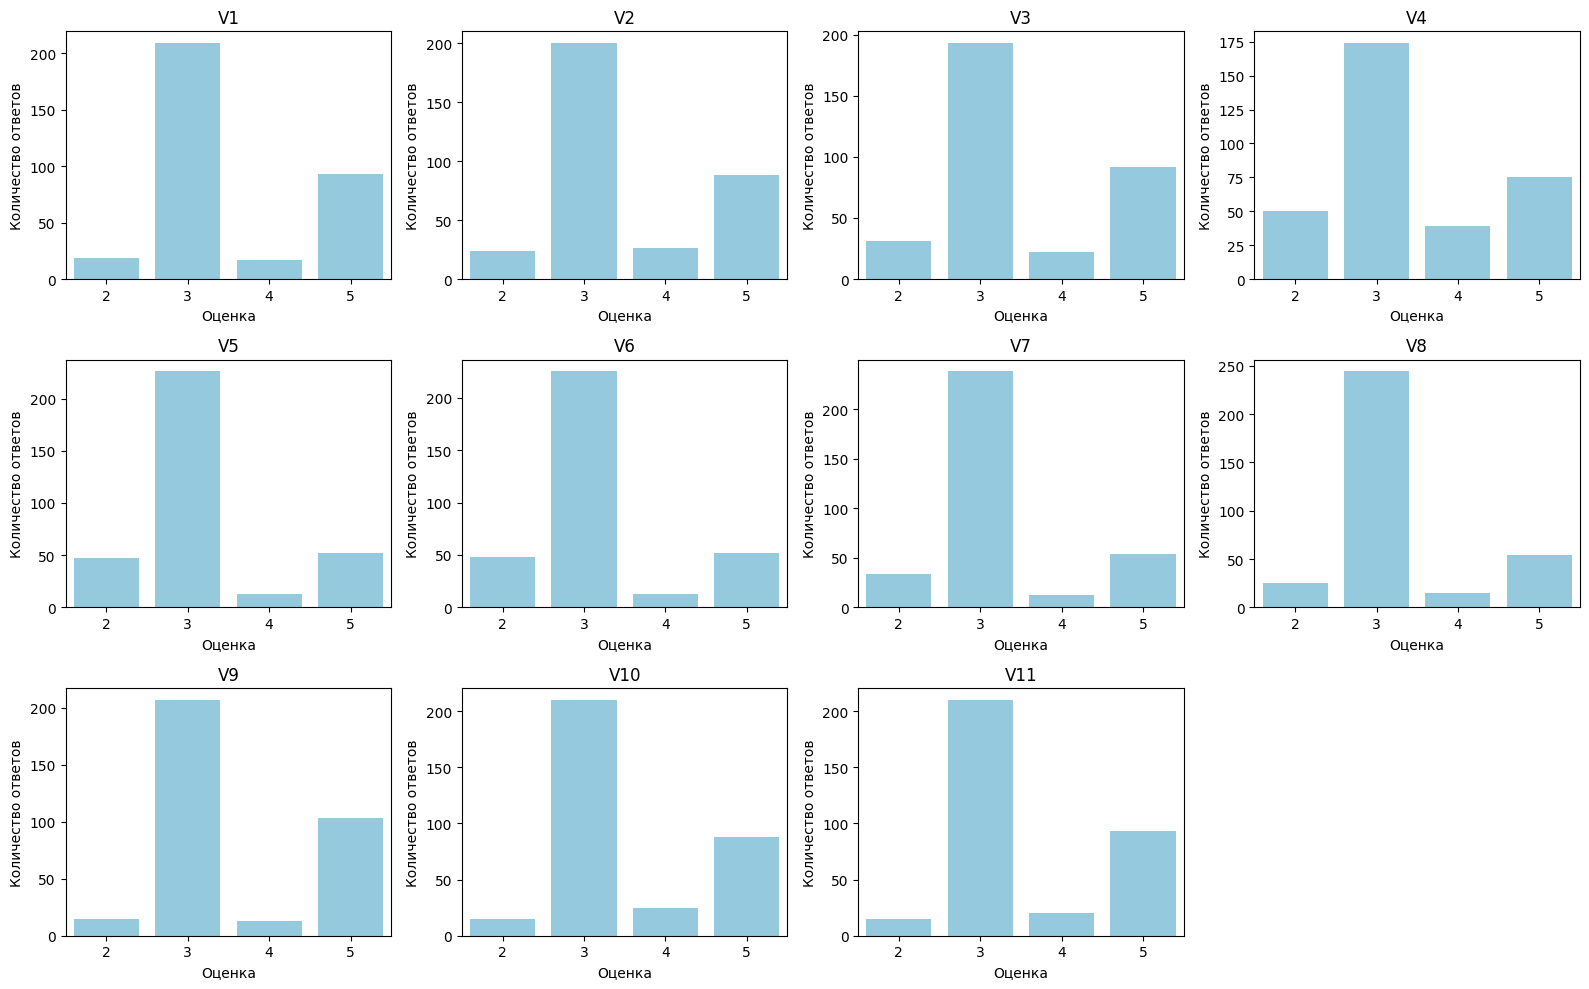

In [6]:
fig, axes = plt.subplots(3, 4, figsize=(16, 10))

for i, col in enumerate(df.columns):
    ax = axes.flat[i]
    sns.countplot(data=df, x=col, ax=ax, color='skyblue')
    ax.set_title(col)
    ax.set_xlabel('Оценка')
    ax.set_ylabel('Количество ответов')

for ax in axes.flat[len(df.columns):]:
    ax.axis('off')

plt.tight_layout()
plt.show()

На всех графиках чаще всего встречается оценка 3. При этом распределения немного отличаются

Для V1–V3 и V9–V11 довольно часто встречается оценка 5. Это вопросы, связанные со свежестью дыхания, уверенностью и облегчением неприятных симптомов

Для V5–V8 ответы сильнее сосредоточены около оценки 3, а максимальные оценки встречаются заметно реже

Пока рассматривается каждый вопрос отдельно. По таким графикам нельзя определить, какие именно группы потребителей есть в выборке, поскольку не видны сочетания ответов одного человека

Поэтому дальше проверим, насколько разные признаки связаны между собой

# **3. Корреляционный анализ**
Перед кластеризацией посмотрим, как связаны между собой разные мотивы употребления леценцов

Для этого построим корреляционную матрицу, которая поможет определить, какие признаки часто изменяются вместе, а какие практически не коррелируют

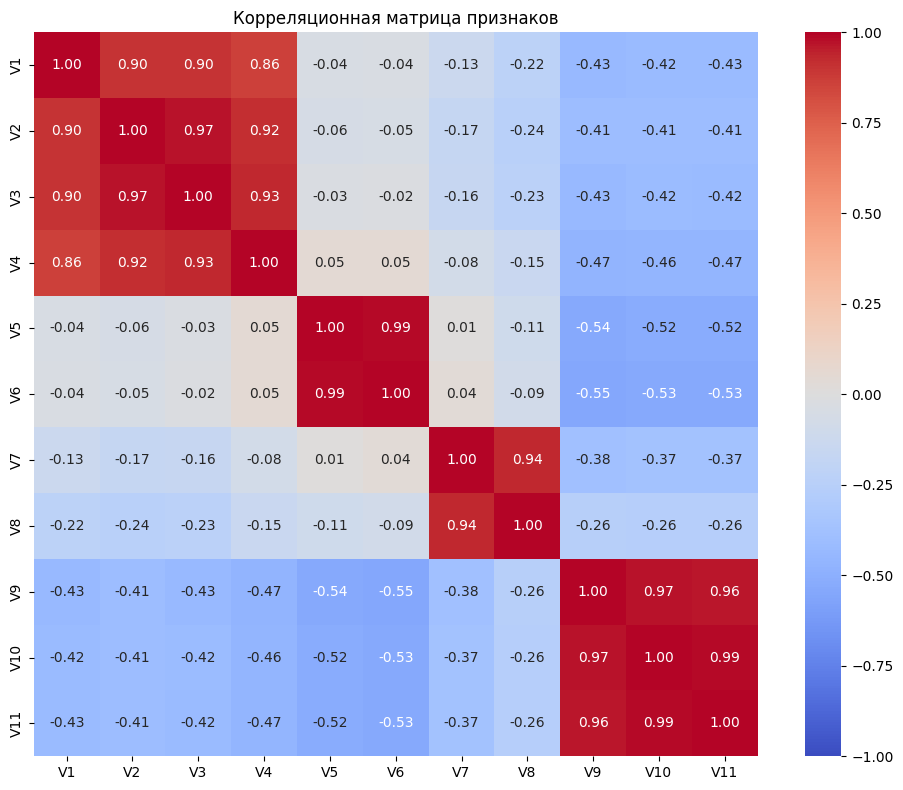

In [7]:
corr_matrix = df.corr()

plt.figure(figsize=(10, 8))

sns.heatmap(
    corr_matrix,
    annot=True,
    fmt='.2f',
    cmap='coolwarm',
    vmin=-1,
    vmax=1,
    square=True
)

plt.title('Корреляционная матрица признаков')
plt.tight_layout()
plt.show()

Вывод по корреляционной матрице
На матрице хорошо выделяются четыре группы сильно связанных признаков:
- V1-V4: свежесть дыхания, полости рта и уверенность. Корреляции от 0,86 до 0,97
- V5-V6: употребление леденцов как сладости. Корреляция 0,99
- V7-V8: концентрация и возможность отвлечься. Корреляция 0,94
- V9-V11: облегчение симптомов и улучшение самочувствия. Корреляции от 0,96 до 0,99
Также заметны отрицательные корреляции между некоторыми группами. Например, между V6 и V9 коэффициент равен -0,55. Это означает, что люди, которые сильнее связывают употребление леденцов с желанием сладкого, в среднем реже высоко оценивают мотив облегчения боли в горле

Получается, что некоторые мотивы действительно связаны между собой, а другие могут противопоставляться друг другу

При этом важно не путать группы признаков с кластерами респондентов. Пока мы нашли только взаимосвязи между вопросами. Самих потребителей на группы будем делить дальше

# **4. Подготовка данных**
В наборе 11 признаков измеряются по одной шкале, а их стандартные отклонения достаточно близки. Поэтому исходные значения будут использованы без стандартизации

Это позволит сохранить первоначальные оценки и избежать дополнительные изменения относительного влияния признаков

Далее будет создана копия таблицы для кластеризации, чтобы исходные данные остались без изменений, и к ним можно было вернуться

In [8]:
X = df.copy()

# **5. Сравнение методов кластеризации**
Для анализа рассмотрим четыре метода объединения кластеров: Single, Complete, Average и Ward

Они отличаются способом определения близости между группами объектов. Например, Single ориентируется на ближайшие объекты, Complete на наиболее удалённые, Average использует среднее расстояние, а Ward старается минимизировать увеличение разброса внутри кластеров

Сначала построим дендрограммы для всех четырех методов. Затем сравним результаты с помощью коэффициента силуэта и проверим, насколько совпадают полученные разбиения

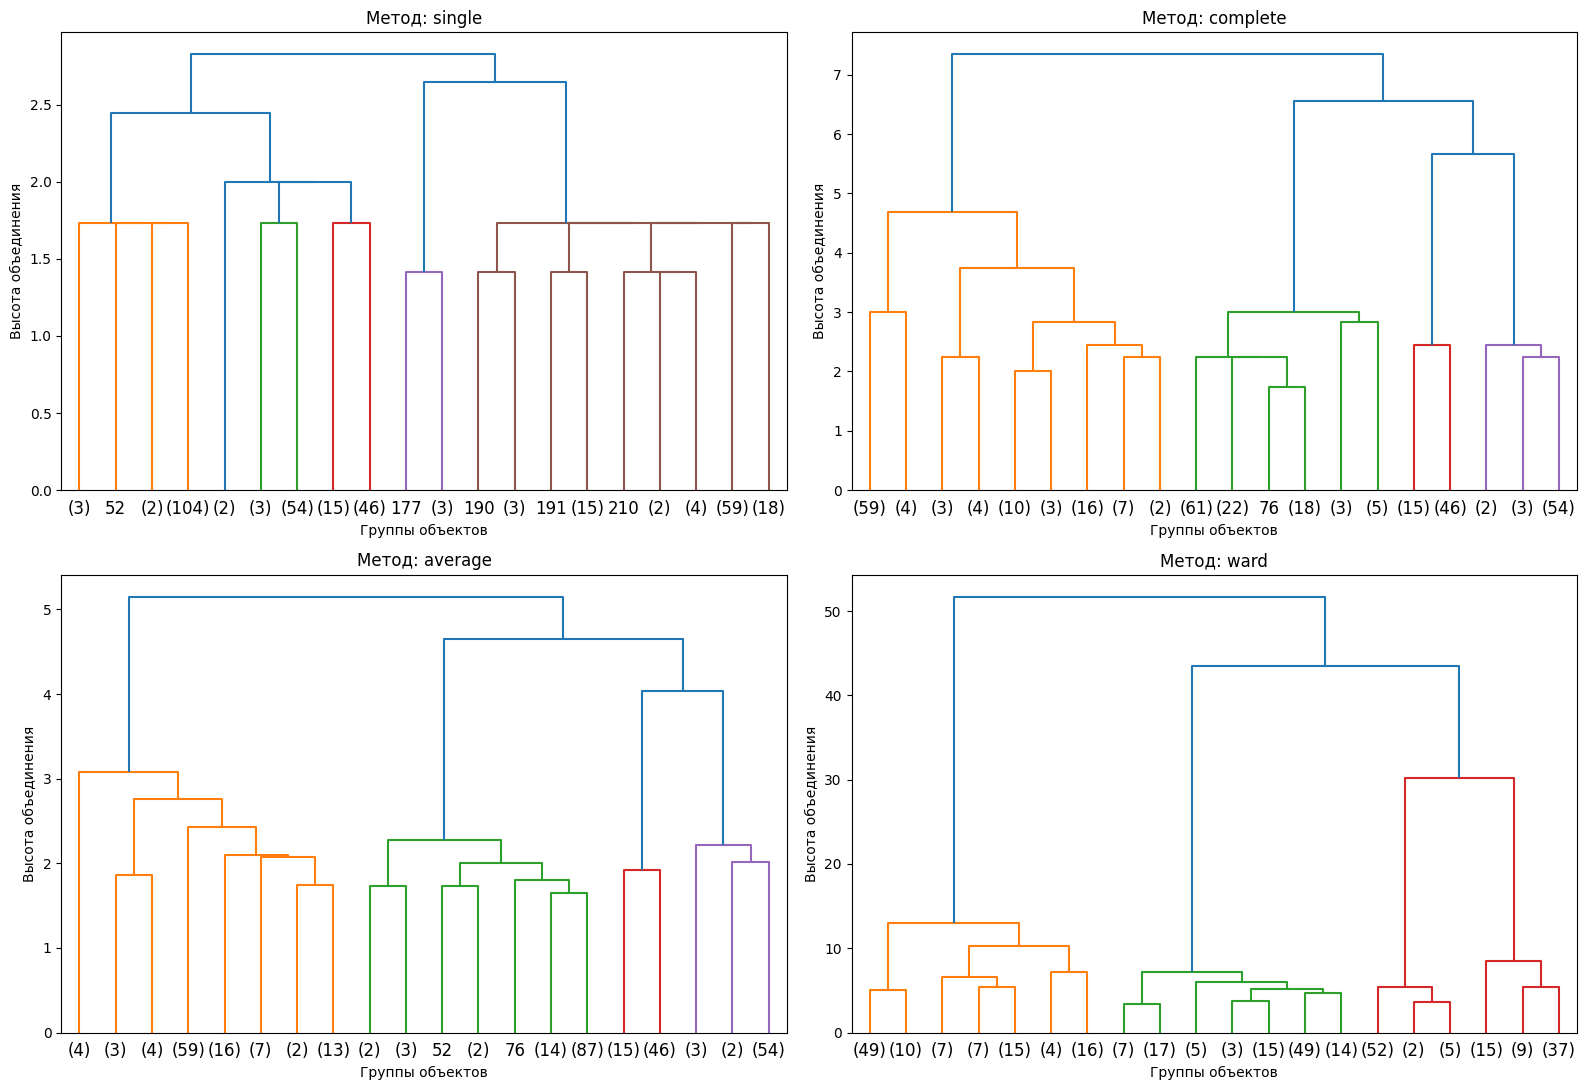

In [9]:
methods = ['single', 'complete', 'average', 'ward']

fig, axes = plt.subplots(2, 2, figsize=(16, 11))

for i, method in enumerate(methods):
    Z = linkage(X, method=method, metric='euclidean')

    dendrogram(
        Z,
        ax=axes.flat[i],
        truncate_mode='lastp',
        p=20,
        show_leaf_counts=True
    )

    axes.flat[i].set_title(f'Метод: {method}')
    axes.flat[i].set_xlabel('Группы объектов')
    axes.flat[i].set_ylabel('Высота объединения')

plt.tight_layout()
plt.show()

## **Сравнение дендрограмм**

По дендрограммам видно, что методы формируют несколько отличающиеся иерархии

У Single многие объединения происходят на близких высотах. Здесь заметен эффект цепочки, когда группы могут соединяться через отдельные близкие объекты

У Complete и Average структура выглядит более выраженной, можно выделить несколько крупных ветвей

На дендрограмме Ward особенно заметны большие промежутки между последними объединениями. Это позволяет предположить, что в данных есть несколько достаточно хорошо отделённых групп

При этом высоты объединений напрямую сравнивать между методами нельзя, поскольку они рассчитываются по разным правилам

Одного визуального анализа недостаточно, поэтому дальше сравним методы количественно

# **6. Количественное сравнение методов**
## **Сравнение по коэффициенту силуэта**

Для каждого метода рассчитаем коэффициент силуэта при разном количестве кластеров

Этот показатель учитывает, насколько объекты близки к своему кластеру и насколько хорошо отделены от соседних групп

Будем проверять варианты от 2 до 10 кластеров. При этом важно учитывать, что максимальный коэффициент силуэта не всегда означает наиболее удобное разбиение для практической задачи

In [10]:
def compare_methods(X, methods, min_k=2, max_k=10):
    results = []

    for method in methods:
        Z = linkage(X, method=method, metric='euclidean')

        for k in range(min_k, max_k + 1):
            labels = fcluster(Z, t=k, criterion='maxclust')
            n_clusters = len(set(labels))

            if n_clusters < 2 or n_clusters >= len(X):
                continue

            score = silhouette_score(X, labels)

            results.append({
                'Метод': method,
                'Кластеры': n_clusters,
                'Silhouette Score': score
            })

    return pd.DataFrame(results)


comparison_results = compare_methods(X, methods)
display(comparison_results.pivot_table(
index='Кластеры',
columns='Метод',
values='Silhouette Score'
).round(3))

Метод,average,complete,single,ward
Кластеры,,,,
2,0.455,0.455,0.455,0.455
3,0.614,0.614,0.374,0.614
4,0.727,0.727,0.560,0.727
5,0.679,0.701,NaN,0.698
6,0.670,0.718,0.671,0.729
7,0.733,NaN,NaN,0.731
8,0.671,0.663,NaN,0.744
9,0.672,NaN,NaN,0.645
10,0.694,0.668,NaN,0.659


## **Результаты сравнения**

Максимальный коэффициент силуэта среди проверенных вариантов получен методом Ward при 8 кластерах и составляет 0,744

При этом при разбиении на 4 кластера методы Ward, Complete и Average показывают одинаковый результат 0,727

Метод Single в целом демонстрирует менее устойчивые показатели при изменении числа кластеров. Его максимальное значение в нашем сравнении составляет 0,671

Интересно, что при четырех кластерах сразу три метода дают одинаковый коэффициент силуэта. Проверим, действительно ли они одинаково распределяют респондентов по группам или совпадает только численное значение показателя

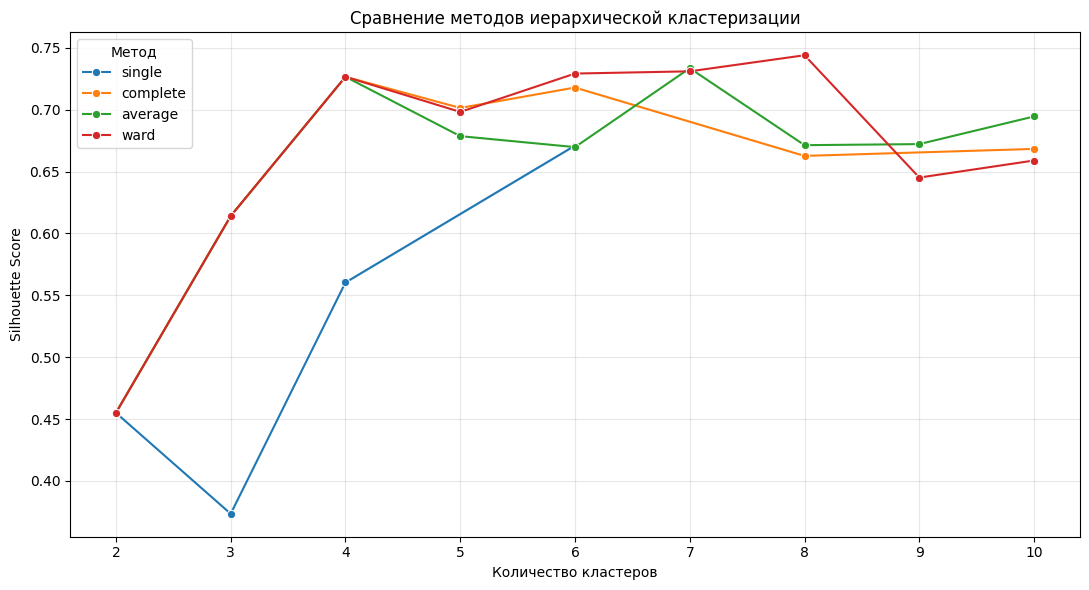

In [11]:
plt.figure(figsize=(11, 6))

sns.lineplot(
    data=comparison_results,
    x='Кластеры',
    y='Silhouette Score',
    hue='Метод',
    marker='o'
)

plt.title('Сравнение методов иерархической кластеризации')
plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.xticks(range(2, 11))
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

# **7. Согласованность методов**
## **Проверка совпадения разбиений**

Чтобы сравнить результаты разных методов, используем скорректированный индекс Рэнда (ARI)

Он позволяет оценить, насколько совпадают два разбиения одних и тех же объектов, независимо от номеров кластеров

Если ARI равен 1, значит, разбиения полностью совпадают

In [12]:
labels_by_method = {}

for method in methods:
    Z = linkage(X, method=method, metric='euclidean')
    labels_by_method[method] = fcluster(
        Z, t=4, criterion='maxclust'
    )

ari_matrix = pd.DataFrame(index=methods, columns=methods)

for method1 in methods:
    for method2 in methods:
        ari_matrix.loc[method1, method2] = adjusted_rand_score(
            labels_by_method[method1],
            labels_by_method[method2]
        )

display(ari_matrix.astype(float).round(3))

,single,complete,average,ward
single,1.000,0.832,0.832,0.832
complete,0.832,1.000,1.000,1.000
average,0.832,1.000,1.000,1.000
ward,0.832,1.000,1.000,1.000


Результаты показали, что методы Ward, Complete и Average при выделении четырех кластеров дают полностью одинаковое разбиение. Значение ARI между ними равно 1

Для Single индекс составляет 0,832. Это тоже достаточно высокая согласованность, но часть респондентов распределена иначе

Таким образом, разбиение на четыре группы не зависит от выбора одного конкретного метода среди Ward, Complete и Average. Это дополнительный аргумент в пользу такого решения

Для дальнейшего анализа выберем Ward. Он показывает высокий коэффициент силуэта, дает хорошо различимые группы и позволяет получить достаточно понятную дендрограмму

# **8. Выбор количества кластеров**

После сравнения методов подробнее рассмотрим результаты Ward

Построим отдельную дендрограмму и оценим, на каких высотах происходят основные объединения. Затем сравним коэффициенты силуэта для разного количества кластеров и размеры полученных групп

Наша задача не просто найти максимальное значение метрики, а выбрать такое количество кластеров, при котором группы будут хорошо разделены и при этом сохранят понятный смысл (что важно для маркетинга)

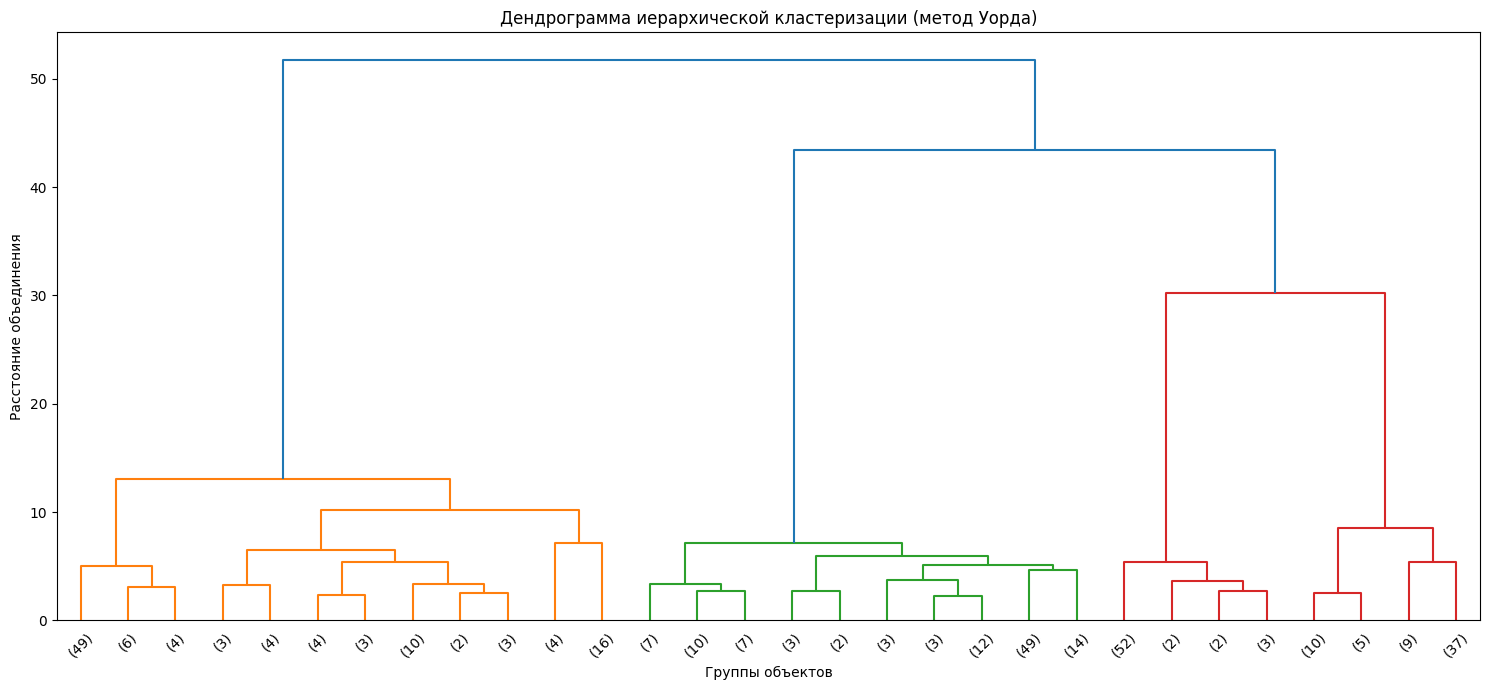

In [13]:
Z_ward = linkage(X, method='ward', metric='euclidean')

plt.figure(figsize=(15, 7))

dendrogram(
    Z_ward,
    truncate_mode='lastp',
    p=30,
    show_leaf_counts=True
)

plt.title('Дендрограмма иерархической кластеризации (метод Уорда)')
plt.xlabel('Группы объектов')
plt.ylabel('Расстояние объединения')

plt.tight_layout()
plt.show()

## **Анализ дендрограммы Ward**

На дендрограмме видны несколько крупных объединений примерно на высотах 13, 30, 43 и 52

Если провести горизонтальный срез между высотами 13 и 30, получим четыре кластера. При более высоком срезе часть групп объединится, а при более низком их количество увеличится

Поэтому четыре кластера выглядят разумным вариантом для дальнейшей проверки

Однако только по дендрограмме окончательное решение принимать не будем. Дополнительно рассмотрим коэффициент силуэта и размеры групп

In [14]:
def evaluate_clusters(X, Z, min_k=2, max_k=10):
    results = []
    for k in range(min_k, max_k + 1):
        labels = fcluster(Z, t=k, criterion='maxclust')
        if len(set(labels)) < 2:
            continue
        score = silhouette_score(X, labels)
        results.append({
            'Количество кластеров': len(set(labels)),
            'Silhouette Score': score
        })
    return pd.DataFrame(results)


silhouette_results = evaluate_clusters(X, Z_ward)
display(silhouette_results.round(3))

,Количество кластеров,Silhouette Score
0,2,0.455
1,3,0.614
2,4,0.727
3,5,0.698
4,6,0.729
5,7,0.731
6,8,0.744
7,9,0.645
8,10,0.659


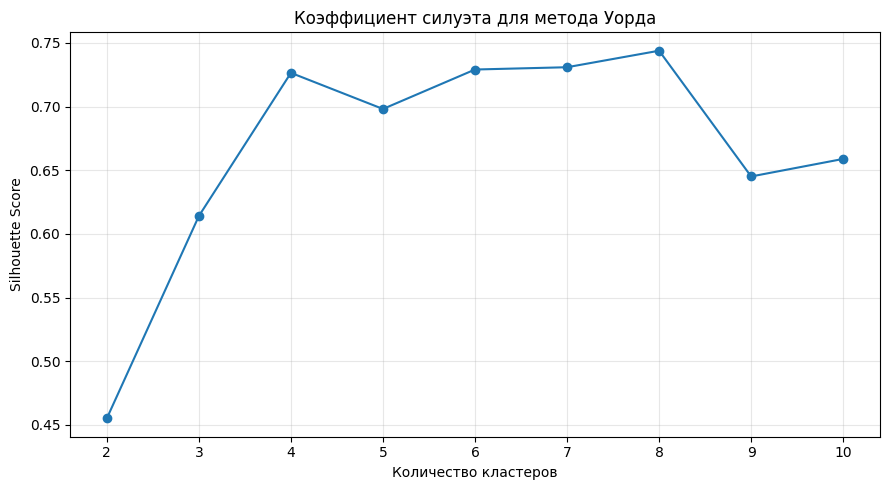

In [15]:
plt.figure(figsize=(9, 5))

plt.plot(
    silhouette_results['Количество кластеров'],
    silhouette_results['Silhouette Score'],
    marker='o'
)

plt.xlabel('Количество кластеров')
plt.ylabel('Silhouette Score')
plt.title('Коэффициент силуэта для метода Уорда')
plt.grid(alpha=0.3)

plt.tight_layout()
plt.show()

In [16]:
labels_4 = fcluster(Z_ward, t=4, criterion='maxclust')
labels_8 = fcluster(Z_ward, t=8, criterion='maxclust')

comparison = pd.DataFrame({
    '4 кластера': pd.Series(labels_4).value_counts().sort_index(),
    '8 кластеров': pd.Series(labels_8).value_counts().sort_index()
})

display(comparison)

,4 кластера,8 кластеров
1,108.0,59
2,110.0,29
3,59.0,4
4,61.0,16
5,NaN,110
6,NaN,59
7,NaN,15
8,NaN,46


# **9. Интерпретация кластеров**

Теперь посмотрим, чем отличаются респонденты из четырёх выделенных групп

Для этого рассчитаем средние оценки каждого признака внутри кластеров и построим тепловую карту

По этим значениям можно определить, какие мотивы наиболее характерны для каждой группы, и предложить содержательные названия сегментов

In [17]:
df_clusters = df.copy()
df_clusters['Кластер'] = labels_4

cluster_profiles = df_clusters.groupby('Кластер').mean()

display(cluster_profiles.round(2))

,V1,V2,V3,V4,V5,V6,V7,V8,V9,V10,V11
Кластер,,,,,,,,,,,
1,2.82,2.83,2.77,2.62,2.61,2.58,2.75,2.92,4.95,4.81,4.86
2,4.85,4.80,4.84,4.68,3.04,3.04,3.00,2.99,3.07,3.05,3.05
3,3.00,2.97,2.97,2.92,2.92,2.95,4.92,4.92,3.00,3.00,3.00
4,3.00,3.00,3.00,3.00,4.85,4.85,3.00,2.92,2.75,2.75,2.75


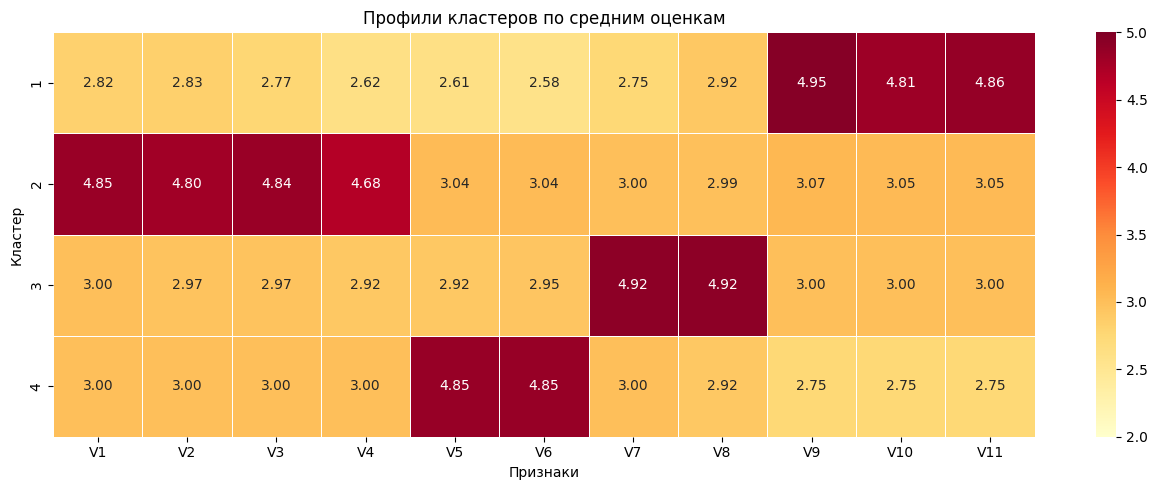

In [18]:
plt.figure(figsize=(13, 5))

sns.heatmap(
    cluster_profiles,
    annot=True,
    fmt='.2f',
    cmap='YlOrRd',
    vmin=2,
    vmax=5,
    linewidths=0.5
)

plt.title('Профили кластеров по средним оценкам')
plt.xlabel('Признаки')
plt.ylabel('Кластер')

plt.tight_layout()
plt.show()

## **Характеристика потребительских сегментов**

По тепловой карте хорошо видно, что у каждого кластера есть свои наиболее выраженные мотивы потребления леденцов

**Кластер 1. Лечебный сегмент**

Включает 108 человек, или 32,0% выборки. Самые высокие оценки у V9–V11, от 4,81 до 4,95

Для этих респондентов леденцы в первую очередь связаны с облегчением боли в горле, заложенности носа и улучшением самочувствия. Остальные мотивы выражены заметно слабее

**Кластер 2. Свежесть и уверенность**

Самая многочисленная группа, 110 человек (32,5%). Высокие оценки наблюдаются по V1–V4, от 4,68 до 4,85

Представители этого сегмента употребляют леденцы прежде всего ради свежести дыхания, ощущения чистоты полости рта и уверенности в себе

**Кластер 3. Концентрация и отвлечение**

Включает 59 человек (17,5%). По V7 и V8 средние оценки составляют 4,92

Для этой группы леденцы связаны с концентрацией внимания и возможностью ненадолго переключиться. По остальным вопросам оценки находятся примерно на уровне 3

**Кластер 4. Леденцы как сладость**

Включает 61 человека (18,0%). По V5 и V6 средние оценки составляют 4,85

Для этих респондентов леденцы в первую очередь являются сладостью или заменой другим кондитерским изделиям. Остальные причины употребления выражены слабее

Полученные группы достаточно хорошо различаются по своим основным мотивам. При этом каждая из них имеет понятную содержательную характеристику, что особенно важно для задачи сегментации потребителей

# **10. Итоговые выводы**

В работе был проведён иерархический кластерный анализ 338 респондентов по 11 признакам, характеризующим причины употребления леденцов

Сначала были изучены исходные данные, проверены пропуски и повторяющиеся наблюдения, построены распределения признаков и корреляционная матрица

Затем мы сравнили четыре метода иерархической кластеризации: Single, Complete, Average и Ward. Для итогового анализа был выбран метод Ward с евклидовой метрикой

На основании дендрограммы, коэффициента силуэта и анализа размеров групп остановились на четырёх кластерах. Коэффициент силуэта составил 0,727. При этом методы Ward, Complete и Average дали одинаковое разбиение на четыре группы, что подтвердилось значением ARI = 1

В результате удалось выделить четыре потребительских сегмента: лечебный, свежесть и уверенность, концентрация и отвлечение, леденцы как сладость

Каждая группа отличается своими ведущими мотивами потребления. Полученные результаты можно использовать для более точного позиционирования продукции и разработки предложений для разных типов покупателей

Таким образом, удалось определить и обосновать количество кластеров, выбрать подходящий метод кластеризации и дать содержательную интерпретацию полученных групп